<a href="https://colab.research.google.com/github/Bhumika363/Food-Delivery-Time-Prediction-/blob/main/Food_Delivery_Time_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mlt
import seaborn as sns
from math import radians, sin, cos, asin, sqrt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [55]:
df=pd.read_csv("/content/Food_Time new.csv")

In [56]:
df.shape

(10000, 17)

In [57]:
df.head()

,Traffic_Level,ID,Delivery_person_ID,weather_description,Type_of_order,Type_of_vehicle,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,temperature,humidity,precipitation,Distance (km),TARGET
0,High,70A2,CHENRES12DEL01,mist,Snack,scooter,32,4.6,12.972.793,80.249.982,13.012.793,80.289.982,26.55,87.0,0.0,9.89,43.45
1,High,95B4,RANCHIRES15DEL01,clear sky,Meal,scooter,33,4.7,23.369.746,8.533.982,23.479.746,8.544.982,17.51,69.0,0.0,19.11,3.816.666.667
2,High,CDCD,DEHRES17DEL01,clear sky,Snack,motorcycle,36,4.2,30.327.968,78.046.106,30.397.968,78.116.106,12.44,77.0,0.0,11.59,3.636.666.667
3,High,2784,PUNERES13DEL03,clear sky,Drinks,scooter,23,4.7,1.856.245,73.916.619,1.865.245,74.006.619,19.37,65.0,0.0,21.93,49.45
4,High,6F67,HYDRES14DEL01,overcast clouds,Snack,motorcycle,34,4.9,17.426.228,78.407.495,17.496.228,78.477.495,21.29,64.0,0.0,18.26,5.248.333.333


In [58]:
df.columns

Index(['Traffic_Level', 'ID', 'Delivery_person_ID', 'weather_description',
       'Type_of_order', 'Type_of_vehicle', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'temperature', 'humidity',
       'precipitation', 'Distance (km)', 'TARGET'],
      dtype='object')

In [59]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,temperature,humidity,precipitation,Distance (km)
count,10000.000000,10000.000000,9995.000000,9995.000000,9995.000000,9080.000000
mean,29.522000,4.629370,22.936907,66.164882,0.016233,14.292747
std,5.700348,0.322941,3.379448,15.602939,0.074911,8.376254
min,15.000000,1.000000,6.770000,27.000000,0.000000,1.550000
25%,25.000000,4.500000,20.140000,54.000000,0.000000,7.620000
50%,29.000000,4.700000,23.000000,67.000000,0.000000,13.400000
75%,34.000000,4.800000,25.980000,81.000000,0.000000,19.610000
max,50.000000,6.000000,29.050000,94.000000,1.460000,59.840000


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Traffic_Level                9085 non-null   object 
 1   ID                           10000 non-null  object 
 2   Delivery_person_ID           10000 non-null  object 
 3   weather_description          9995 non-null   object 
 4   Type_of_order                10000 non-null  object 
 5   Type_of_vehicle              10000 non-null  object 
 6   Delivery_person_Age          10000 non-null  int64  
 7   Delivery_person_Ratings      10000 non-null  float64
 8   Restaurant_latitude          10000 non-null  object 
 9   Restaurant_longitude         10000 non-null  object 
 10  Delivery_location_latitude   10000 non-null  object 
 11  Delivery_location_longitude  10000 non-null  object 
 12  temperature                  9995 non-null   float64
 13  humidity         

In [61]:
df.isnull().sum()

,0
Traffic_Level,915
ID,0
Delivery_person_ID,0
weather_description,5
Type_of_order,0
Type_of_vehicle,0
Delivery_person_Age,0
Delivery_person_Ratings,0
Restaurant_latitude,0
Restaurant_longitude,0


In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
cleaned_df = df.copy()

In [64]:
print("Original shape:", cleaned_df.shape)

Original shape: (10000, 17)


In [65]:
print(cleaned_df['Traffic_Level'].value_counts(dropna=False))

Traffic_Level
High         2736
Moderate     2219
Very High    1772
Low          1726
NaN           915
Very Low      632
Name: count, dtype: int64


In [66]:
cleaned_df['Traffic_Level'] = cleaned_df['Traffic_Level'].fillna('Unknown')

In [67]:
print(cleaned_df['Traffic_Level'].value_counts())

Traffic_Level
High         2736
Moderate     2219
Very High    1772
Low          1726
Unknown       915
Very Low      632
Name: count, dtype: int64


In [68]:
weather_mode = cleaned_df['weather_description'].mode()[0]
cleaned_df['weather_description'] = cleaned_df['weather_description'].fillna(weather_mode)
print("Weather mode used:", weather_mode)

Weather mode used: clear sky


In [69]:
numeric_columns = ['temperature', 'humidity', 'precipitation']
for col in numeric_columns:
    median_value = cleaned_df[col].median()
    cleaned_df[col] = cleaned_df[col].fillna(median_value)
    print(f"{col} median used: {median_value}")

temperature median used: 23.0
humidity median used: 67.0
precipitation median used: 0.0


In [70]:
cleaned_df = cleaned_df.dropna(subset=['TARGET'])
print("Shape after removing missing TARGET:", cleaned_df.shape)

Shape after removing missing TARGET: (9459, 17)


In [71]:
def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * asin(sqrt(a))
    return 6371 * c

In [72]:
print(cleaned_df.columns.tolist())

['Traffic_Level', 'ID', 'Delivery_person_ID', 'weather_description', 'Type_of_order', 'Type_of_vehicle', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'temperature', 'humidity', 'precipitation', 'Distance (km)', 'TARGET']


In [73]:
coordinate_columns = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]
for col in coordinate_columns:
    cleaned_df[col] = pd.to_numeric(cleaned_df[col], errors='coerce')

In [74]:
print(cleaned_df[coordinate_columns].dtypes)

Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
dtype: object


In [75]:
missing_distance = cleaned_df['Distance (km)'].isna()
cleaned_df.loc[missing_distance, 'Distance (km)'] = cleaned_df.loc[missing_distance].apply(
    lambda row: haversine_distance(
        row['Restaurant_latitude'],
        row['Restaurant_longitude'],
        row['Delivery_location_latitude'],
        row['Delivery_location_longitude']
    ),
    axis=1
)

In [76]:
print("Missing Distance values:", cleaned_df['Distance (km)'].isna().sum())

Missing Distance values: 117


In [77]:
missing_distance_rows = cleaned_df[cleaned_df['Distance (km)'].isna()]
print(missing_distance_rows[
    [
        'Restaurant_latitude',
        'Restaurant_longitude',
        'Delivery_location_latitude',
        'Delivery_location_longitude'
    ]].isnull().sum())

Restaurant_latitude            114
Restaurant_longitude           117
Delivery_location_latitude     114
Delivery_location_longitude    117
dtype: int64


In [78]:
cleaned_df = cleaned_df.dropna(
    subset=[
        'Restaurant_latitude',
        'Restaurant_longitude',
        'Delivery_location_latitude',
        'Delivery_location_longitude'
    ])
print("Shape after removing rows with missing coordinates:", cleaned_df.shape)

Shape after removing rows with missing coordinates: (337, 17)


In [79]:
print("Missing Distance values:",cleaned_df['Distance (km)'].isna().sum())

Missing Distance values: 0


In [80]:
cleaned_df = cleaned_df.dropna(
    subset=[
        'Restaurant_latitude',
        'Restaurant_longitude',
        'Delivery_location_latitude',
        'Delivery_location_longitude'
    ])
print("Shape after removing incomplete coordinate rows:", cleaned_df.shape)

Shape after removing incomplete coordinate rows: (337, 17)


In [81]:
print("Missing Distance values:",cleaned_df['Distance (km)'].isna().sum())

Missing Distance values: 0


In [82]:
print(cleaned_df.isnull().sum())

Traffic_Level                  0
ID                             0
Delivery_person_ID             0
weather_description            0
Type_of_order                  0
Type_of_vehicle                0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
temperature                    0
humidity                       0
precipitation                  0
Distance (km)                  0
TARGET                         0
dtype: int64


In [83]:
categorical_columns = [
    'Traffic_Level',
    'weather_description',
    'Type_of_order',
    'Type_of_vehicle'
]
for col in categorical_columns:
    print(f"\n{col}:")
    print(cleaned_df[col].value_counts())


Traffic_Level:
Traffic_Level
Unknown     307
Moderate     13
High          9
Low           6
Very Low      2
Name: count, dtype: int64

weather_description:
weather_description
broken clouds      184
overcast clouds    123
haze                16
clear sky           14
Name: count, dtype: int64

Type_of_order:
Type_of_order
Snack     89
Buffet    86
Meal      82
Drinks    80
Name: count, dtype: int64

Type_of_vehicle:
Type_of_vehicle
motorcycle          185
scooter             122
electric_scooter     29
bicycle               1
Name: count, dtype: int64


In [84]:
numeric_columns = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'temperature',
    'humidity',
    'precipitation',
    'Distance (km)',
    'TARGET']
print(cleaned_df[numeric_columns].describe())

       Delivery_person_Age  Delivery_person_Ratings  temperature    humidity  \
count           337.000000               337.000000   337.000000  337.000000   
mean             29.620178                 4.612463    26.001276   81.735905   
std               5.621330                 0.335178     1.018302    9.160197   
min              20.000000                 2.500000    18.910000   42.000000   
25%              25.000000                 4.500000    26.260000   84.000000   
50%              30.000000                 4.700000    26.270000   84.000000   
75%              34.000000                 4.800000    26.280000   85.000000   
max              39.000000                 5.000000    26.280000   85.000000   

       precipitation  Distance (km)  
count          337.0     337.000000  
mean             0.0      12.548776  
std              0.0       4.645317  
min              0.0       2.740000  
25%              0.0       9.435202  
50%              0.0      12.580268  
75%          

In [85]:
outlier_columns = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'temperature',
    'humidity',
    'Distance (km)']
for col in outlier_columns:
    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = cleaned_df[
        (cleaned_df[col] < lower_bound) |
        (cleaned_df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers")

Delivery_person_Age: 0 outliers
Delivery_person_Ratings: 25 outliers
temperature: 30 outliers
humidity: 30 outliers
Distance (km): 9 outliers


In [86]:
for col in outlier_columns:
    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    print(f"\n{col}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Minimum: {cleaned_df[col].min():.2f}")
    print(f"Maximum: {cleaned_df[col].max():.2f}")


Delivery_person_Age
Lower bound: 11.50
Upper bound: 47.50
Minimum: 20.00
Maximum: 39.00

Delivery_person_Ratings
Lower bound: 4.05
Upper bound: 5.25
Minimum: 2.50
Maximum: 5.00

temperature
Lower bound: 26.23
Upper bound: 26.31
Minimum: 18.91
Maximum: 26.28

humidity
Lower bound: 82.50
Upper bound: 86.50
Minimum: 42.00
Maximum: 85.00

Distance (km)
Lower bound: 2.36
Upper bound: 21.23
Minimum: 2.74
Maximum: 27.44


In [87]:
print(cleaned_df['TARGET'].describe())

count         337
unique         31
top       #VALUE!
freq          307
Name: TARGET, dtype: object


In [88]:
print(cleaned_df['TARGET'].value_counts().head(40))

TARGET
#VALUE!          307
4.271.666.667      1
4.096.666.667      1
39.35              1
4.336.666.667      1
5.141.666.667      1
4.216.666.667      1
4.966.666.667      1
4.591.666.667      1
27.85              1
1.613.333.333      1
22.9               1
2.198.333.333      1
2.536.666.667      1
46.25              1
21.8               1
2.328.333.333      1
3.066.666.667      1
3.738.333.333      1
26.6               1
3.368.333.333      1
3.248.333.333      1
3.208.333.333      1
2.831.666.667      1
30.9               1
2.806.666.667      1
30.6               1
2.971.666.667      1
22.05              1
10.15              1
9.1                1
Name: count, dtype: int64


In [89]:
valid_target = cleaned_df[cleaned_df['TARGET'] != '#VALUE!']['TARGET']
print("Number of valid TARGET values:", len(valid_target))
print("\nExact TARGET values:")
print(valid_target.tolist())

Number of valid TARGET values: 30

Exact TARGET values:
['4.096.666.667', '4.271.666.667', '4.216.666.667', '39.35', '4.336.666.667', '5.141.666.667', '46.25', '4.966.666.667', '4.591.666.667', '27.85', '1.613.333.333', '22.9', '2.198.333.333', '2.536.666.667', '21.8', '2.328.333.333', '3.738.333.333', '3.066.666.667', '3.208.333.333', '26.6', '3.368.333.333', '3.248.333.333', '2.831.666.667', '30.9', '30.6', '2.806.666.667', '2.971.666.667', '22.05', '10.15', '9.1']


In [90]:
print(df['TARGET'].head(20).tolist())

['43.45', '3.816.666.667', '3.636.666.667', '49.45', '5.248.333.333', '3.461.666.667', '4.416.666.667', '5.438.333.333', '4.746.666.667', '4.728.333.333', '46.25', '4.061.666.667', '4.418.333.333', '46.45', '50.35', '4.971.666.667', '42.3', '4.548.333.333', '4.558.333.333', '3.636.666.667']


In [91]:
print(df.loc[df['TARGET'].astype(str).str.count(r'\.') > 1,['TARGET', 'Distance (km)', 'Delivery_person_Age', 'Delivery_person_Ratings']].head(20))

           TARGET  Distance (km)  Delivery_person_Age  Delivery_person_Ratings
1   3.816.666.667          19.11                   33                      4.7
2   3.636.666.667          11.59                   36                      4.2
4   5.248.333.333          18.26                   34                      4.9
5   3.461.666.667           8.97                   25                      4.0
6   4.416.666.667          16.08                   35                      4.3
7   5.438.333.333          26.35                   32                      4.6
8   4.746.666.667          17.24                   33                      4.9
9   4.728.333.333          12.08                   22                      4.8
11  4.061.666.667          13.20                   23                      4.9
12  4.418.333.333          11.37                   27                      4.9
15  4.971.666.667          19.07                   24                      4.7
17  4.548.333.333          11.19                   2

In [92]:
target_check = df['TARGET'].astype(str)
print(
    target_check[
        target_check.str.count(r'\.') > 1
    ].str.replace('.', '', regex=False).head(20).tolist())

['3816666667', '3636666667', '5248333333', '3461666667', '4416666667', '5438333333', '4746666667', '4728333333', '4061666667', '4418333333', '4971666667', '4548333333', '4558333333', '3636666667', '4021666667', '4791666667', '4681666667', '5281666667', '5231666667', '4573333333']


In [93]:
def clean_target(value):
    value = str(value)
    if value == '#VALUE!':
        return np.nan
    if value.count('.') > 1:
        return float(value.replace('.', '')) / 100000000
    return float(value)
cleaned_df['TARGET'] = cleaned_df['TARGET'].apply(clean_target)
print(cleaned_df['TARGET'].describe())

count    30.000000
mean     31.431111
std      10.883973
min       9.100000
25%      23.804167
50%      30.633333
75%      40.562500
max      51.416667
Name: TARGET, dtype: float64


In [94]:
cleaned_df = cleaned_df.dropna(subset=['TARGET'])
print("Shape after removing invalid TARGET rows:", cleaned_df.shape)
print("Missing TARGET values:", cleaned_df['TARGET'].isna().sum())

Shape after removing invalid TARGET rows: (30, 17)
Missing TARGET values: 0


In [95]:
print("Final Shape:", cleaned_df.shape)
print("\nMissing values:")
print(cleaned_df.isnull().sum())
print("\nData Types:")
print(cleaned_df.dtypes)

Final Shape: (30, 17)

Missing values:
Traffic_Level                  0
ID                             0
Delivery_person_ID             0
weather_description            0
Type_of_order                  0
Type_of_vehicle                0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
temperature                    0
humidity                       0
precipitation                  0
Distance (km)                  0
TARGET                         0
dtype: int64

Data Types:
Traffic_Level                   object
ID                              object
Delivery_person_ID              object
weather_description             object
Type_of_order                   object
Type_of_vehicle                 object
Delivery_person_Age              int64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude   

In [96]:
X = cleaned_df[
    ['Delivery_person_Age',
     'Delivery_person_Ratings',
     'temperature',
     'humidity',
     'precipitation',
     'Distance (km)',
     'Traffic_Level',
     'weather_description',
     'Type_of_order',
     'Type_of_vehicle']]
y = cleaned_df['TARGET']
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.head())

Features shape: (30, 10)
Target shape: (30,)

Features:
      Delivery_person_Age  Delivery_person_Ratings  temperature  humidity  \
302                    20                      4.6        22.43      44.0   
498                    29                      4.6        22.43      44.0   
1240                   23                      4.9        18.91      82.0   
1335                   24                      4.6        18.94      82.0   
1511                   35                      4.3        25.94      57.0   

      precipitation  Distance (km) Traffic_Level weather_description  \
302             0.0          23.95          High           clear sky   
498             0.0          23.95          High           clear sky   
1240            0.0          27.44          High                haze   
1335            0.0          23.45          High                haze   
1511            0.0          23.45          High                haze   

     Type_of_order Type_of_vehicle  
302        

In [97]:
categorical_columns = [
    'Traffic_Level',
    'weather_description',
    'Type_of_order',
    'Type_of_vehicle']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_encoded = encoder.fit_transform(X[categorical_columns])
print("Encoded feature shape:", X_encoded.shape)

Encoded feature shape: (30, 13)


In [98]:
numerical_columns = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'temperature',
    'humidity',
    'precipitation',
    'Distance (km)']
X_numerical = X[numerical_columns].values
X_final = np.hstack((X_numerical, X_encoded))
print("Final feature shape:", X_final.shape)

Final feature shape: (30, 19)


In [99]:
X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.2, random_state=42)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (24, 19)
Testing features: (6, 19)
Training target: (24,)
Testing target: (6,)


In [100]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [101]:
y_pred = linear_model.predict(X_test)
print("Predicted values:")
print(y_pred)

Predicted values:
[27.02723142 28.55055566 12.96832705 30.08411112 32.93568511 25.59745669]


In [102]:
comparison = pd.DataFrame({'Actual Delivery Time': y_test.values,'Predicted Delivery Time': y_pred})
print(comparison)

   Actual Delivery Time  Predicted Delivery Time
0             22.050000                27.027231
1             23.283333                28.550556
2             30.900000                12.968327
3             30.666667                30.084111
4             45.916667                32.935685
5             27.850000                25.597457


In [103]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 7.332034520635151
MSE: 91.33009384476829
RMSE: 9.5566779711764
R² Score: -0.49126889316305267


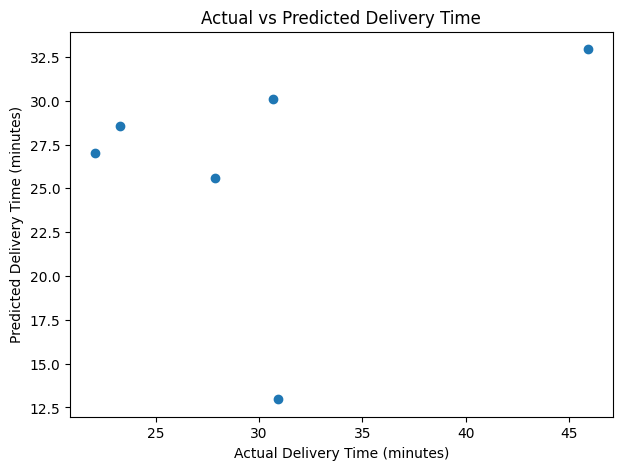

In [104]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.show()

In [105]:
print("Number of coefficients:", len(linear_model.coef_))
print("Intercept:", linear_model.intercept_)
print("Coefficients:")
print(linear_model.coef_)

Number of coefficients: 19
Intercept: 190.6865503033663
Coefficients:
[ 9.80648735e-03 -2.67967905e+00 -3.95803550e+00 -1.21204315e+00
  1.34336986e-14  4.98957214e-01  1.06514201e+01 -3.47662413e+00
  2.50164381e+00 -9.67643974e+00 -1.60530585e+01  1.60530585e+01
 -3.08492215e-01  4.89894524e+00 -3.65622715e+00 -9.34225877e-01
  1.66010922e+00 -3.98473199e-01 -1.26163602e+00]


In [106]:
X_distance = cleaned_df[['Distance (km)']]
y = cleaned_df['TARGET']
X_train_dist, X_test_dist, y_train_dist, y_test_dist = train_test_split(X_distance, y, test_size=0.2, random_state=42)
simple_model = LinearRegression()
simple_model.fit(X_train_dist, y_train_dist)
y_pred_simple = simple_model.predict(X_test_dist)
print("Simple Linear Regression trained successfully.")
print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Simple Linear Regression trained successfully.
Coefficient: 1.410271915305522
Intercept: 8.837728741673448


In [107]:
mae_simple = mean_absolute_error(y_test_dist, y_pred_simple)
mse_simple = mean_squared_error(y_test_dist, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)
r2_simple = r2_score(y_test_dist, y_pred_simple)
print("Simple Linear Regression Results")
print("MAE:", mae_simple)
print("MSE:", mse_simple)
print("RMSE:", rmse_simple)
print("R² Score:", r2_simple)

Simple Linear Regression Results
MAE: 4.029643223020427
MSE: 21.380161708094295
RMSE: 4.623868694945207
R² Score: 0.6508974343082505


In [108]:
comparison_metrics = pd.DataFrame({'Metric': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Simple Linear Regression': [
        mae_simple,
        mse_simple,
        rmse_simple,
        r2_simple
    ],
    'Multiple Linear Regression': [
        mae,
        mse,
        rmse,
        r2]})
print(comparison_metrics)

     Metric  Simple Linear Regression  Multiple Linear Regression
0       MAE                  4.029643                    7.332035
1       MSE                 21.380162                   91.330094
2      RMSE                  4.623869                    9.556678
3  R² Score                  0.650897                   -0.491269


In [109]:
new_distance = np.array([[10]])
predicted_time = simple_model.predict(new_distance)
print("Distance:", new_distance[0][0], "km")
print("Predicted Delivery Time:", predicted_time[0], "minutes")

Distance: 10 km
Predicted Delivery Time: 22.94044789472867 minutes


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [110]:
new_order = pd.DataFrame({'Distance (km)': [10]})
predicted_time = simple_model.predict(new_order)
print("Distance:", new_order['Distance (km)'].iloc[0], "km")
print("Predicted Delivery Time:", predicted_time[0], "minutes")

Distance: 10 km
Predicted Delivery Time: 22.94044789472867 minutes


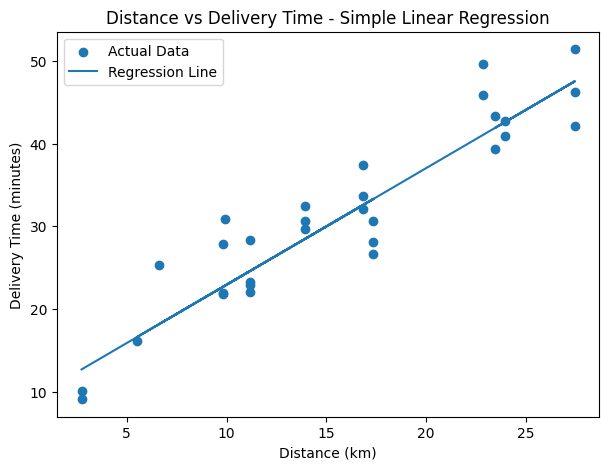

In [111]:
plt.figure(figsize=(7, 5))
plt.scatter(X_distance, y, label="Actual Data")
plt.plot(X_distance,simple_model.predict(X_distance),label="Regression Line")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.title("Distance vs Delivery Time - Simple Linear Regression")
plt.legend()
plt.show()

In [112]:
print("PROJECT FINAL CHECK")
print("-------------------")
print("Dataset shape:", cleaned_df.shape)
print("\nSimple Linear Regression:")
print("MAE:", mae_simple)
print("RMSE:", rmse_simple)
print("R² Score:", r2_simple)
print("\nMultiple Linear Regression:")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)
print("\nNew Order Prediction:")
print("Distance: 10 km")
print("Predicted Delivery Time:", predicted_time[0], "minutes")

PROJECT FINAL CHECK
-------------------
Dataset shape: (30, 17)

Simple Linear Regression:
MAE: 4.029643223020427
RMSE: 4.623868694945207
R² Score: 0.6508974343082505

Multiple Linear Regression:
MAE: 7.332034520635151
RMSE: 9.5566779711764
R² Score: -0.49126889316305267

New Order Prediction:
Distance: 10 km
Predicted Delivery Time: 22.94044789472867 minutes
